<a href="https://colab.research.google.com/github/ghbigbrain/discrete-mathetics-project/blob/main/OOP_Python_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐍 Lập trình hướng đối tượng với Python — Notebook thực hành
**Object-Oriented Programming with Python · Lab notebook** · Giảng viên: **Trần Hùng**

Notebook đi kèm bài giảng 120 phút (slide VI/EN + lecture notes). Bạn sẽ đi từ class đầu tiên đến một hệ thống quản lý sinh viên đọc dữ liệu thật từ CSV.

| Phần | Nội dung | Thời gian |
|---|---|---|
| 0 | Chuẩn bị dữ liệu | 2' |
| A | Class & object | 10' |
| B | `__init__`, `self`, `__str__` | 10' |
| C | Method & trạng thái — tái hiện sao kê ngân hàng từ CSV | 15' |
| D | Encapsulation — kiểm tra dữ liệu khi đọc CSV | 15' |
| E | Inheritance & polymorphism | 10' |
| F | Mini project: Student Management System + biểu đồ | 20' |
| G | Bài tập có ô **tự chấm** | 30' |
| H | Lời giải tham khảo | — |

### ▶️ Cách chạy trên Google Colab
1. Mở [colab.research.google.com](https://colab.research.google.com) → **File → Upload notebook** → chọn file này.
2. Chọn **Runtime → Run all**. Không cần tải CSV lên: ô Phần 0 tự tạo dữ liệu nếu chưa có.
3. (Tuỳ chọn) Tải thư mục `data/` của gói tài liệu lên Colab để dùng file gốc.

> 💡 Quy ước: ô có dòng `# TODO` là chỗ bạn viết code. Các ô kiểm tra **không bao giờ làm dừng notebook** — chúng chỉ báo ✅ / ⏳ / ❌.

## 0 · Chuẩn bị dữ liệu

In [ ]:
#@title Tạo thư mục `data/` và các file CSV (tự động nếu chưa có) { display-mode: "form" }
from pathlib import Path

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

EMBEDDED = {
    'students.csv': '''student_id,full_name,gender,birth_year,major,cohort,gpa,credits,email
SV001,Nguyen Minh Duc,M,2005,Data Science,2023,2.99,79,duc.nguyen01@student.edu.vn
SV002,Nguyen Thi Chi,F,2005,Finance Technology,2023,2.3,80,chi.nguyen02@student.edu.vn
SV003,Do Duc Quan,M,2007,Computer Science,2025,2.67,32,quan.do03@student.edu.vn
SV004,Vu Thu Ha,F,2005,Data Science,2023,3.18,93,ha.vu04@student.edu.vn
SV005,Tran Thu Uyen,F,2004,Finance Technology,2024,3.04,50,uyen.tran05@student.edu.vn
SV006,Dang Van Minh,M,2004,Finance Technology,2024,3.2,53,minh.dang06@student.edu.vn
SV007,Ly Van An,M,2005,Business Analytics,2023,4.0,93,an.ly07@student.edu.vn
SV008,Bui Thu Ha,F,2006,Digital Marketing,2024,2.96,58,ha.bui08@student.edu.vn
SV009,Ly Thi Nhung,F,2003,Information Systems,2023,3.01,84,nhung.ly09@student.edu.vn
SV010,Duong Minh Tuan,M,2004,Information Systems,2022,2.75,127,tuan.duong10@student.edu.vn
SV011,Hoang Thi Hoa,F,2006,Business Analytics,2024,2.77,44,hoa.hoang11@student.edu.vn
SV012,Hoang Duc Duc,M,2004,Finance Technology,2024,4.35,51,duc.hoang12@student.edu.vn
SV013,Vu Ngoc Ha,F,2007,Digital Marketing,2025,3.09,28,ha.vu13@student.edu.vn
SV014,Duong Quang Nam,M,2003,Finance Technology,2022,2.06,116,nam.duong14@student.edu.vn
SV015,Do Thu Ngoc,F,2004,Digital Marketing,2022,2.79,120,ngoc.do15@student.edu.vn
SV016,Tran Thu Linh,F,2004,Digital Marketing,2023,2.49,96,linh.tran16@student.edu.vn
SV017,Do Ngoc Ngoc,F,2004,Computer Science,2022,3.37,122,ngoc.do17@student.edu.vn
SV018,Le Phuong Trang,F,2002,Business Analytics,2022,2.55,118,trang.le18@student.edu.vn
SV019,Tran Minh Viet,M,2006,Data Science,2024,4.0,62,viet.tran19@student.edu.vn
SV020,Tran Phuong Trang,F,2005,Business Analytics,2023,3.42,75,trang.tran20@student.edu.vn
SV021,Hoang Huu Tuan,M,2007,Computer Science,2025,3.81,10,tuan.hoang21@student.edu.vn
SV022,Dang Thu Mai,F,2007,Computer Science,2025,2.69,25,mai.dang22@student.edu.vn
SV023,Vu Van Nam,M,2003,Data Science,2023,3.09,76,nam.vu23@student.edu.vn
SV024,Tran Van Tuan,M,2006,Computer Science,2024,,48,tuan.tran24@student.edu.vn
SV025,Duong Thanh Hoa,F,2003,Business Analytics,2023,2.72,81,hoa.duong25@student.edu.vn
SV026,Tran Van Phong,M,2007,Business Analytics,2025,2.88,19,phong.tran26@student.edu.vn
SV027,Ly Thi Phuong,F,2004,Computer Science,2022,2.68,125,phuong.ly27@student.edu.vn
SV028,Pham Huu Long,M,2004,Information Systems,2023,3.31,91,long.pham28@student.edu.vn
SV029,Pham Thi Mai,F,2004,Data Science,2022,2.69,128,mai.pham29@student.edu.vn
SV030,Le Quang Long,M,2007,Data Science,2025,2.54,20,long.le30@student.edu.vn
SV031,Dang Van Khanh,M,2005,Finance Technology,2024,2.88,41,khanh.dang31@student.edu.vn
SV032,Le Ngoc Huong,F,2005,Digital Marketing,2023,3.8,78,huong.le32@student.edu.vn
SV033,Ly Minh An,M,2002,Computer Science,2022,1.94,112,an.ly33@student.edu.vn
SV034,Do Van Tuan,M,2005,Data Science,2023,3.21,77,tuan.do34@student.edu.vn
SV035,Dang Van Viet,M,2003,Digital Marketing,2023,2.47,83,viet.dang35@student.edu.vn
SV036,Hoang Ngoc Phuong,F,2006,Business Analytics,2024,2.66,56,phuong.hoang36@student.edu.vn
SV037,Duong Minh Long,M,2006,Data Science,2024,3.75,46,long.duong37@student.edu.vn
SV038,Do Duc Minh,M,2006,Data Science,2024,3.09,-12,minh.do38@student.edu.vn
SV039,Vu Minh Cuong,M,2005,Digital Marketing,2025,2.85,7,cuong.vu39@student.edu.vn
SV040,Duong Huu Hai,M,2004,Data Science,2022,2.39,120,hai.duong40@student.edu.vn
SV041,Ly Huu Cuong,M,2006,Digital Marketing,2024,2.42,58,cuong.ly41@student.edu.vn
SV042,Do Thanh Huong,F,2004,Business Analytics,2022,2.56,108,huong.do42@student.edu.vn
SV043,Nguyen Thi Lan,F,2005,Business Analytics,2023,3.33,74,lan.nguyen43@student.edu.vn
SV044,Tran Van Viet,M,2003,Information Systems,2023,3.51,95,viet.tran44@student.edu.vn
SV045,Dang Duc An,M,2006,Information Systems,2024,3.77,63,an.dang45@student.edu.vn
SV046,Duong Duc Phong,M,2004,Finance Technology,2022,2.52,104,phong.duong46@student.edu.vn
SV047,Ngo Ngoc Yen,F,2005,Data Science,2023,3.95,83,yen.ngo47@student.edu.vn
SV048,Ly Minh Son,M,2007,Computer Science,2025,2.91,24,son.ly48@student.edu.vn
SV049,Dang Van Tuan,M,2007,Information Systems,2025,3.4,21,
SV050,Pham Van Phong,M,2004,Information Systems,2023,4.0,86,phong.pham50@student.edu.vn
SV051,Hoang Minh Phong,M,2005,Computer Science,2025,2.99,24,phong.hoang51@student.edu.vn
SV052,Nguyen Thi Nhung,F,2007,Information Systems,2025,3.15,9,nhung.nguyen52@student.edu.vn
SV053,Ngo Phuong Chi,F,2005,Data Science,2025,three,19,chi.ngo53@student.edu.vn
SV054,Vu Quang Binh,M,2004,Digital Marketing,2024,3.19,54,binh.vu54@student.edu.vn
SV055,Ly Minh Minh,M,2005,Computer Science,2024,2.69,47,minh.ly55@student.edu.vn
SV056,Dang Quang Phong,M,2003,Information Systems,2023,3.74,78,phong.dang56@student.edu.vn
SV057,Do Thi Huong,F,2006,Information Systems,2024,2.45,44,huong.do57@student.edu.vn
SV058,Bui Thanh Phuong,F,2003,Digital Marketing,2023,3.33,81,phuong.bui58@student.edu.vn
SV059,Duong Van Hai,M,2006,Information Systems,2024,3.4,43,hai.duong59@student.edu.vn
SV060,Pham Duc An,M,2004,Finance Technology,2022,2.29,113,an.pham60@student.edu.vn
''',
    'accounts.csv': '''account_id,owner,opening_balance
ACC01,Nguyen Van An,1000
ACC02,Tran Thi Lan,2500
ACC03,Le Minh Duc,300
''',
    'bank_transactions.csv': '''txn_id,date,account_id,type,amount
T001,2026-09-01,ACC01,deposit,500
T002,2026-09-02,ACC02,withdraw,700
T003,2026-09-03,ACC03,deposit,200
T004,2026-09-04,ACC01,withdraw,300
T005,2026-09-05,ACC03,withdraw,900
T006,2026-09-06,ACC02,deposit,-50
T007,2026-09-07,ACC01,deposit,1200
T008,2026-09-08,ACC02,withdraw,400
T009,2026-09-09,ACC03,deposit,450
T010,2026-09-10,ACC01,withdraw,5000
T011,2026-09-11,ACC02,deposit,800
T012,2026-09-12,ACC03,withdraw,150
T013,2026-09-13,ACC01,withdraw,250
T014,2026-09-14,ACC02,withdraw,0
T015,2026-09-15,ACC03,deposit,1000
T016,2026-09-16,ACC01,deposit,75
T017,2026-09-17,ACC02,withdraw,1200
T018,2026-09-18,ACC03,withdraw,600
T019,2026-09-19,ACC01,withdraw,400
T020,2026-09-20,ACC02,deposit,300
T021,2026-09-21,ACC03,deposit,50
T022,2026-09-22,ACC01,deposit,600
T023,2026-09-23,ACC02,withdraw,2000
T024,2026-09-24,ACC03,withdraw,300
''',
    'products.csv': '''product_id,name,category,price,quantity,warranty_months
P001,Laptop Pro 14,Electronics,28990000,8,24
P002,Wireless Mouse,Electronics,390000,45,12
P003,Mechanical Keyboard,Electronics,1850000,20,12
P004,USB-C Hub,Electronics,650000,3,6
P005,Notebook A5,Stationery,35000,300,
P006,Gel Pen (box),Stationery,85000,120,
P007,Desk Lamp,Furniture,450000,15,
P008,Ergonomic Chair,Furniture,3200000,4,
P009,"Monitor 27""",Electronics,5490000,10,36
P010,Backpack,Accessories,690000,25,
P011,Water Bottle,Accessories,150000,2,
P012,Webcam HD,Electronics,990000,12,12
''',
}

for name, content in EMBEDDED.items():
    path = DATA_DIR / name
    if not path.exists():
        path.write_text(content, encoding='utf-8')
        print(f'✔ created  {path}')
    else:
        print(f'• found    {path}')

✔ created  data/students.csv
✔ created  data/accounts.csv
✔ created  data/bank_transactions.csv
✔ created  data/products.csv


In [ ]:
import csv
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 120)
students_df = pd.read_csv('data/students.csv')
print(students_df.shape)
students_df.head()

(60, 9)


,student_id,full_name,gender,birth_year,major,cohort,gpa,credits,email
0,SV001,Nguyen Minh Duc,M,2005,Data Science,2023,2.99,79,duc.nguyen01@student.edu.vn
1,SV002,Nguyen Thi Chi,F,2005,Finance Technology,2023,2.3,80,chi.nguyen02@student.edu.vn
2,SV003,Do Duc Quan,M,2007,Computer Science,2025,2.67,32,quan.do03@student.edu.vn
3,SV004,Vu Thu Ha,F,2005,Data Science,2023,3.18,93,ha.vu04@student.edu.vn
4,SV005,Tran Thu Uyen,F,2004,Finance Technology,2024,3.04,50,uyen.tran05@student.edu.vn


Bộ dữ liệu có **60 sinh viên**. Có **5 dòng lỗi được cố ý cài vào** (GPA ngoài khoảng, GPA trống, GPA không phải số, tín chỉ âm, thiếu email) để bạn thực hành kiểm tra dữ liệu ở Phần D. Hãy thử tìm chúng bằng pandas:

In [ ]:
gpa_num = pd.to_numeric(students_df['gpa'], errors='coerce')
suspicious = students_df[gpa_num.isna() | (gpa_num > 4) | (students_df['credits'] < 0) | students_df['email'].isna()]
suspicious

,student_id,full_name,gender,birth_year,major,cohort,gpa,credits,email
11,SV012,Hoang Duc Duc,M,2004,Finance Technology,2024,4.35,51,duc.hoang12@student.edu.vn
23,SV024,Tran Van Tuan,M,2006,Computer Science,2024,NaN,48,tuan.tran24@student.edu.vn
37,SV038,Do Duc Minh,M,2006,Data Science,2024,3.09,-12,minh.do38@student.edu.vn
48,SV049,Dang Van Tuan,M,2007,Information Systems,2025,3.4,21,NaN
52,SV053,Ngo Phuong Chi,F,2005,Data Science,2025,three,19,chi.ngo53@student.edu.vn


---
## A · Class & object
Class là **bản thiết kế**; object là **thực thể cụ thể** tạo từ class.

In [ ]:
class Student:
    pass

s1 = Student()
s2 = Student()
print(type(s1))
print(isinstance(s1, Student))
print(s1 is s2)          # two different objects

<class '__main__.Student'>
True
False


In [ ]:
# Attributes can be attached with dot notation ...
s1.name = 'An'
s1.gpa = 3.5
s2.name = 'Binh'          # ... but it is easy to forget one!

print(s1.name, s1.gpa)
print(hasattr(s2, 'gpa'))  # False -> s2 has no gpa

An 3.5
False


> 🔎 **Dự đoán trước khi chạy:** `print(s2.gpa)` sẽ in ra gì? Thử bỏ dấu `#` ở ô dưới để kiểm chứng.

In [ ]:
# print(s2.gpa)   # AttributeError: 'Student' object has no attribute 'gpa'

---
## B · `__init__`, `self` và `__str__`
`__init__` được gọi **tự động** khi tạo object. `self` là **object đứng trước dấu chấm**.

In [ ]:
class Student:
    school = 'OOP Academy'                    # class attribute (shared)

    def __init__(self, student_id, name, gpa=0.0):
        self.student_id = student_id          # instance attributes
        self.name = name
        self.gpa = gpa

    def hello(self):
        print(f'Hi, I am {self.name}')

    def __str__(self):
        return f'Student({self.student_id}, {self.name}, GPA={self.gpa})'

an = Student('SV001', 'An', 3.7)
lan = Student('SV002', 'Lan')                 # gpa uses the default value
an.hello()
Student.hello(an)                             # exactly what Python does behind the scenes
print(an)
print(lan)
print(an.school, lan.school)

Hi, I am An
Hi, I am An
Student(SV001, An, GPA=3.7)
Student(SV002, Lan, GPA=0.0)
OOP Academy OOP Academy


---
## C · Method & trạng thái — tái hiện sao kê ngân hàng
Mỗi lời gọi method có thể **thay đổi trạng thái** của object. Ta đọc `accounts.csv` và `bank_transactions.csv`, rồi áp từng giao dịch lên các object `BankAccount`.
Giao dịch không hợp lệ (số tiền ≤ 0, rút quá số dư) phải bị **từ chối**, nhưng chương trình vẫn chạy tiếp.

In [ ]:
class BankAccount:
    def __init__(self, account_id, owner, balance=0):
        self.account_id = account_id
        self.owner = owner
        self._balance = float(balance)        # internal: change only via methods
        self.history = []

    def deposit(self, amount):
        if amount <= 0:
            raise ValueError('Deposit amount must be positive')
        self._balance += amount
        self.history.append(('deposit', amount))

    def withdraw(self, amount):
        if amount <= 0:
            raise ValueError('Withdraw amount must be positive')
        if amount > self._balance:
            raise ValueError('Not enough money')
        self._balance -= amount
        self.history.append(('withdraw', amount))

    @property
    def balance(self):                         # read-only
        return self._balance

    def __str__(self):
        return f'{self.account_id} | {self.owner:<15} | {self._balance:>10,.0f}'

In [ ]:
accounts = {}
with open('data/accounts.csv', encoding='utf-8') as f:
    for row in csv.DictReader(f):
        acc = BankAccount(row['account_id'], row['owner'], float(row['opening_balance']))
        accounts[acc.account_id] = acc

rejected = []
with open('data/bank_transactions.csv', encoding='utf-8') as f:
    for row in csv.DictReader(f):
        acc = accounts[row['account_id']]
        amount = float(row['amount'])
        try:
            if row['type'] == 'deposit':
                acc.deposit(amount)
            else:
                acc.withdraw(amount)
        except ValueError as err:
            rejected.append((row['txn_id'], row['account_id'], row['type'], amount, str(err)))

print('Final balances')
for acc in accounts.values():
    print(acc)
print(f'\nRejected transactions: {len(rejected)}')
pd.DataFrame(rejected, columns=['txn_id', 'account', 'type', 'amount', 'reason'])

Final balances
ACC01 | Nguyen Van An   |      2,425
ACC02 | Tran Thi Lan    |      1,300
ACC03 | Le Minh Duc     |        950

Rejected transactions: 5


,txn_id,account,type,amount,reason
0,T005,ACC03,withdraw,900.0,Not enough money
1,T006,ACC02,deposit,-50.0,Deposit amount must be positive
2,T010,ACC01,withdraw,5000.0,Not enough money
3,T014,ACC02,withdraw,0.0,Withdraw amount must be positive
4,T023,ACC02,withdraw,2000.0,Not enough money


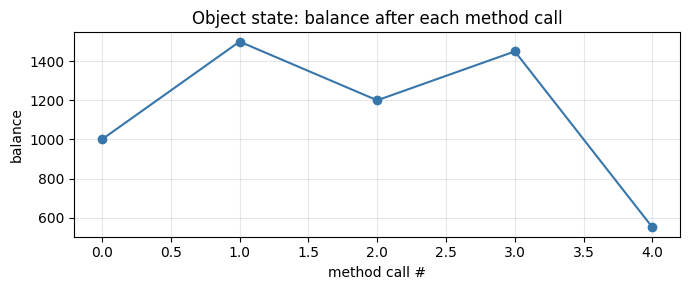

In [ ]:
# State over time for one account
acc = BankAccount('DEMO', 'Demo', 1000)
timeline = [acc.balance]
for kind, amount in [('deposit', 500), ('withdraw', 300), ('deposit', 250), ('withdraw', 900)]:
    getattr(acc, kind)(amount)
    timeline.append(acc.balance)

plt.figure(figsize=(7, 3))
plt.plot(timeline, marker='o', color='#3776AB')
plt.title('Object state: balance after each method call')
plt.xlabel('method call #'); plt.ylabel('balance')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

> ✏️ **Thử ngay:** gọi `acc.balance = 0`. Vì sao Python từ chối? (Gợi ý: `@property` không có setter.)

---
## D · Encapsulation — kiểm tra dữ liệu khi tạo object
Ta đặt quy tắc trong class: GPA phải là số trong `[0, 4]`, tín chỉ không âm, email bắt buộc. Object **không thể** được tạo với dữ liệu sai, vì vậy dữ liệu lỗi bị chặn ngay từ cửa.

In [ ]:
class Student:
    def __init__(self, student_id, name, major, gpa, credits, email):
        self.student_id = student_id
        self.name = name
        self.major = major
        self.gpa = gpa                 # goes through the property setter below
        self.credits = int(credits)
        if self.credits < 0:
            raise ValueError(f'credits must be >= 0, got {credits}')
        if not email:
            raise ValueError('email is required')
        self.email = email

    @property
    def gpa(self):
        return self._gpa

    @gpa.setter
    def gpa(self, value):
        value = float(value)           # raises ValueError for '' or 'three'
        if not 0 <= value <= 4:
            raise ValueError(f'GPA must be in [0, 4], got {value}')
        self._gpa = value

    def get_grade(self):
        if self.gpa >= 3.6:
            return 'Excellent'
        elif self.gpa >= 3.2:
            return 'Good'
        elif self.gpa >= 2.5:
            return 'Fair'
        elif self.gpa >= 2.0:
            return 'Average'
        return 'Weak'

    def __str__(self):
        return f'{self.student_id} {self.name:<22} {self.gpa:.2f}  {self.get_grade()}'

In [ ]:
def load_students(path):
    valid, errors = [], []
    with open(path, encoding='utf-8') as f:
        for row in csv.DictReader(f):
            try:
                s = Student(row['student_id'], row['full_name'], row['major'],
                            row['gpa'], row['credits'], row['email'])
                valid.append(s)
            except ValueError as err:
                errors.append({'student_id': row['student_id'], 'error': str(err)})
    return valid, errors

students, errors = load_students('data/students.csv')
print(f'Loaded {len(students)} valid students, rejected {len(errors)} rows')
pd.DataFrame(errors)

Loaded 55 valid students, rejected 5 rows


,student_id,error
0,SV012,"GPA must be in [0, 4], got 4.35"
1,SV024,could not convert string to float: ''
2,SV038,"credits must be >= 0, got -12"
3,SV049,email is required
4,SV053,could not convert string to float: 'three'


In [ ]:
s = students[0]
print(s)
try:
    s.gpa = 5.0                     # the setter protects the rule
except ValueError as err:
    print('Blocked:', err)
print('GPA is still', s.gpa)

SV001 Nguyen Minh Duc        2.99  Fair
Blocked: GPA must be in [0, 4], got 5.0
GPA is still 2.99


---
## E · Inheritance & polymorphism
`GraduateStudent` **là một** `Student`: kế thừa mọi thứ, gọi `super().__init__()` và **ghi đè** `__str__`.

In [ ]:
class GraduateStudent(Student):
    def __init__(self, student_id, name, major, gpa, credits, email, thesis_title):
        super().__init__(student_id, name, major, gpa, credits, email)
        self.thesis_title = thesis_title

    def __str__(self):                                   # override
        return super().__str__() + f'  [thesis: {self.thesis_title}]'

class ExchangeStudent(Student):
    def __init__(self, student_id, name, major, gpa, credits, email, home_university):
        super().__init__(student_id, name, major, gpa, credits, email)
        self.home_university = home_university

    def get_grade(self):                                 # override: pass/fail only
        return 'Pass' if self.gpa >= 2.0 else 'Fail'

people = [
    students[1],
    GraduateStudent('GS01', 'Nguyen Khanh', 'AI', 3.8, 150, 'khanh@uni.edu', 'AI for Education'),
    ExchangeStudent('EX01', 'Emma Schmidt', 'Data Science', 2.9, 30, 'emma@tum.de', 'TU Munich'),
]
for p in people:                    # same call, different behaviour
    print(p)
print(isinstance(people[1], Student), issubclass(ExchangeStudent, Student))

SV002 Nguyen Thi Chi         2.30  Average
GS01 Nguyen Khanh           3.80  Excellent  [thesis: AI for Education]
EX01 Emma Schmidt           2.90  Pass
True True


---
## F · Mini project — Student Management System
`StudentManager` **chứa** nhiều `Student` (quan hệ *has-a*) và cung cấp các báo cáo.

In [ ]:
class StudentManager:
    GRADE_ORDER = ['Excellent', 'Good', 'Fair', 'Average', 'Weak']

    def __init__(self, students=None):
        self.students = list(students or [])

    def add(self, student):
        self.students.append(student)

    def __len__(self):
        return len(self.students)

    def average_gpa(self):
        if not self.students:
            return 0.0
        return sum(s.gpa for s in self.students) / len(self.students)

    def best_student(self):
        return max(self.students, key=lambda s: s.gpa)

    def top(self, n=5):
        return sorted(self.students, key=lambda s: s.gpa, reverse=True)[:n]

    def filter_by_grade(self, grade):
        return [s for s in self.students if s.get_grade() == grade]

    def count_by_grade(self):
        counts = {g: 0 for g in self.GRADE_ORDER}
        for s in self.students:
            counts[s.get_grade()] += 1
        return counts

    def to_dataframe(self):
        return pd.DataFrame([{'student_id': s.student_id, 'name': s.name, 'major': s.major,
                              'gpa': s.gpa, 'credits': s.credits, 'grade': s.get_grade()}
                             for s in self.students])

manager = StudentManager(students)
print(f'Students     : {len(manager)}')
print(f'Average GPA  : {manager.average_gpa():.2f}')
print(f'Best student : {manager.best_student()}')
print('\nTop 5')
for s in manager.top(5):
    print(' ', s)
print('\nCount by grade:', manager.count_by_grade())

Students     : 55
Average GPA  : 3.00
Best student : SV007 Ly Van An              4.00  Excellent

Top 5
  SV007 Ly Van An              4.00  Excellent
  SV019 Tran Minh Viet         4.00  Excellent
  SV050 Pham Van Phong         4.00  Excellent
  SV047 Ngo Ngoc Yen           3.95  Excellent
  SV021 Hoang Huu Tuan         3.81  Excellent

Count by grade: {'Excellent': 9, 'Good': 9, 'Fair': 28, 'Average': 8, 'Weak': 1}


In [ ]:
df = manager.to_dataframe()
summary = (df.groupby('major')
             .agg(students=('student_id', 'count'), avg_gpa=('gpa', 'mean'), max_gpa=('gpa', 'max'))
             .round(2).sort_values('avg_gpa', ascending=False))
summary

,students,avg_gpa,max_gpa
major,,,
Information Systems,10,3.31,4.00
Data Science,10,3.18,4.00
Business Analytics,9,2.99,4.00
Digital Marketing,10,2.94,3.80
Computer Science,9,2.86,3.81
Finance Technology,7,2.61,3.20


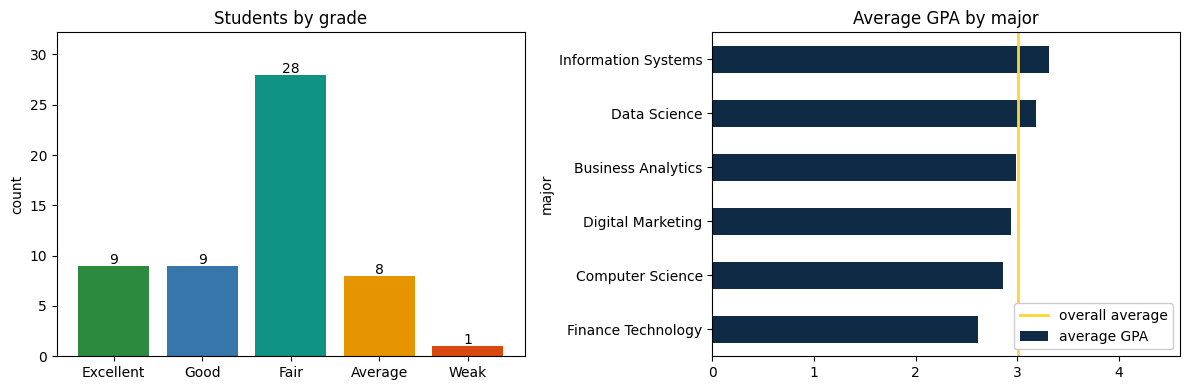

In [ ]:
counts = manager.count_by_grade()
colors = ['#2B8A3E', '#3776AB', '#0E9384', '#E69500', '#D9480F']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(counts.keys(), counts.values(), color=colors)
axes[0].set_title('Students by grade'); axes[0].set_ylabel('count')
axes[0].set_ylim(0, max(counts.values()) * 1.15)
for i, v in enumerate(counts.values()):
    axes[0].text(i, v + 0.2, str(v), ha='center')

summary['avg_gpa'].sort_values().plot.barh(ax=axes[1], color='#0F2A44', label='average GPA')
axes[1].axvline(manager.average_gpa(), color='#FFD43B', lw=2, label='overall average')
axes[1].set_title('Average GPA by major'); axes[1].set_xlim(0, 4.6)
axes[1].legend(loc='lower right', framealpha=1)
plt.tight_layout(); plt.show()

---
## G · Bài tập có ô tự chấm
Viết code vào các ô `# TODO`, rồi chạy ô kiểm tra ngay bên dưới.
Trạng thái: ✅ đúng · ⏳ chưa làm · ❌ sai (kèm gợi ý).

In [ ]:
def check(title, test):
    """Run a test function without ever stopping the notebook."""
    try:
        test()
        print(f'✅ {title}')
    except (NotImplementedError, NameError):
        print(f'⏳ {title}: not implemented yet')
    except AssertionError as err:
        print(f'❌ {title}: {err}')
    except Exception as err:
        print(f'❌ {title}: {type(err).__name__}: {err}')

### Bài 1 ★ — `Rectangle`
Thuộc tính `width`, `height`; method `area()`, `perimeter()`, `is_square()`.

In [ ]:
class Rectangle:
    def __init__(self, width, height):
        # TODO: store width and height
        raise NotImplementedError

    def area(self):
        raise NotImplementedError   # TODO

    def perimeter(self):
        raise NotImplementedError   # TODO

    def is_square(self):
        raise NotImplementedError   # TODO

In [ ]:
def test_rectangle():
    r = Rectangle(5, 3)
    assert r.area() == 15, 'area of 5x3 should be 15'
    assert r.perimeter() == 16, 'perimeter of 5x3 should be 16'
    assert not r.is_square() and Rectangle(4, 4).is_square(), 'is_square is wrong'
check('Exercise 1 - Rectangle', test_rectangle)

⏳ Exercise 1 - Rectangle: not implemented yet


### Bài 2 ★★ — `Product` và `Inventory` (dùng `data/products.csv`)
- `Product(product_id, name, category, price, quantity)` với `get_total_value()`, `sell(q)`, `restock(q)`.
- `sell(q)` ném `ValueError` nếu `q <= 0` hoặc `q` lớn hơn tồn kho; `restock(q)` ném `ValueError` nếu `q <= 0`.
- `Inventory` có `add(p)`, `total_value()`, `most_expensive()`, `low_stock(threshold=5)` (trả về list sản phẩm có `quantity < threshold`).

In [ ]:
class Product:
    def __init__(self, product_id, name, category, price, quantity):
        raise NotImplementedError   # TODO

    def get_total_value(self):
        raise NotImplementedError   # TODO

    def sell(self, q):
        raise NotImplementedError   # TODO

    def restock(self, q):
        raise NotImplementedError   # TODO


class Inventory:
    def __init__(self):
        raise NotImplementedError   # TODO

    def add(self, product):
        raise NotImplementedError   # TODO

    def total_value(self):
        raise NotImplementedError   # TODO

    def most_expensive(self):
        raise NotImplementedError   # TODO

    def low_stock(self, threshold=5):
        raise NotImplementedError   # TODO

In [ ]:
def test_inventory():
    inv = Inventory()
    with open('data/products.csv', encoding='utf-8') as f:
        for row in csv.DictReader(f):
            inv.add(Product(row['product_id'], row['name'], row['category'],
                            float(row['price']), int(row['quantity'])))
    assert round(inv.total_value()) == 413_000_000, f'total_value is {inv.total_value()}'
    assert inv.most_expensive().product_id == 'P001', 'most_expensive should be P001'
    assert sorted(p.product_id for p in inv.low_stock()) == ['P004', 'P008', 'P011'], 'low_stock is wrong'
    p = Product('X', 'Test', 'Misc', 10, 5)
    p.sell(3); p.restock(10)
    assert p.quantity == 12, 'sell/restock do not update quantity'
    for bad in (lambda: p.sell(100), lambda: p.sell(0), lambda: p.restock(-1)):
        try:
            bad()
        except ValueError:
            continue
        raise AssertionError('invalid sell/restock must raise ValueError')
check('Exercise 2 - Product & Inventory', test_inventory)

⏳ Exercise 2 - Product & Inventory: not implemented yet


### Bài 3 ★★ — Thêm method cho `StudentManager`
Viết hàm `students_above_average(manager)` trả về list `student_id` của các sinh viên có GPA **lớn hơn** GPA trung bình, sắp xếp tăng dần theo `student_id`.

In [ ]:
def students_above_average(manager):
    # TODO
    raise NotImplementedError

In [ ]:
def test_above_average():
    avg = manager.average_gpa()
    expected = sorted(s.student_id for s in manager.students if s.gpa > avg)
    result = students_above_average(manager)
    assert result == expected, f'expected {len(expected)} ids, got {len(result)}'
check('Exercise 3 - students_above_average', test_above_average)

⏳ Exercise 3 - students_above_average: not implemented yet


### Bài 4 ★★★ — `ElectronicProduct(Product)`
Thêm `warranty_months`; gọi `super().__init__()`; ghi đè `__str__` để trả về dạng `"P001 Laptop Pro 14 (24m warranty)"`.

In [ ]:
# TODO: define class ElectronicProduct(Product)

In [ ]:
def test_electronic():
    e = ElectronicProduct('P001', 'Laptop Pro 14', 'Electronics', 28_990_000, 8, 24)
    assert isinstance(e, Product), 'ElectronicProduct must inherit from Product'
    assert e.get_total_value() == 231_920_000, 'inherited get_total_value is wrong'
    assert str(e) == 'P001 Laptop Pro 14 (24m warranty)', f'__str__ returned {str(e)!r}'
check('Exercise 4 - ElectronicProduct', test_electronic)

⏳ Exercise 4 - ElectronicProduct: not implemented yet


---
## H · Lời giải tham khảo
⚠️ Hãy tự làm trước! Chạy các ô dưới đây sẽ **định nghĩa lại** các class bằng lời giải mẫu và chấm lại toàn bộ.

In [ ]:
class Rectangle:
    def __init__(self, width, height):
        self.width = width
        self.height = height

    def area(self):
        return self.width * self.height

    def perimeter(self):
        return 2 * (self.width + self.height)

    def is_square(self):
        return self.width == self.height


class Product:
    def __init__(self, product_id, name, category, price, quantity):
        self.product_id = product_id
        self.name = name
        self.category = category
        self.price = price
        self.quantity = quantity

    def get_total_value(self):
        return self.price * self.quantity

    def sell(self, q):
        if q <= 0 or q > self.quantity:
            raise ValueError(f'cannot sell {q} (stock: {self.quantity})')
        self.quantity -= q

    def restock(self, q):
        if q <= 0:
            raise ValueError('restock quantity must be positive')
        self.quantity += q

    def __str__(self):
        return f'{self.product_id} {self.name}'


class Inventory:
    def __init__(self):
        self.products = []

    def add(self, product):
        self.products.append(product)

    def total_value(self):
        return sum(p.get_total_value() for p in self.products)

    def most_expensive(self):
        return max(self.products, key=lambda p: p.price)

    def low_stock(self, threshold=5):
        return [p for p in self.products if p.quantity < threshold]


def students_above_average(manager):
    avg = manager.average_gpa()
    return sorted(s.student_id for s in manager.students if s.gpa > avg)


class ElectronicProduct(Product):
    def __init__(self, product_id, name, category, price, quantity, warranty_months):
        super().__init__(product_id, name, category, price, quantity)
        self.warranty_months = warranty_months

    def __str__(self):
        return f'{super().__str__()} ({self.warranty_months}m warranty)'

In [ ]:
check('Exercise 1 - Rectangle', test_rectangle)
check('Exercise 2 - Product & Inventory', test_inventory)
check('Exercise 3 - students_above_average', test_above_average)
check('Exercise 4 - ElectronicProduct', test_electronic)

✅ Exercise 1 - Rectangle
✅ Exercise 2 - Product & Inventory
✅ Exercise 3 - students_above_average
✅ Exercise 4 - ElectronicProduct


---
## ✅ Tổng kết
- **Class** = bản thiết kế, **object** = thực thể; `__init__` khởi tạo, `self` = object hiện tại.
- **Method** đọc/thay đổi **trạng thái**; `__str__` giúp in object dễ đọc.
- **Encapsulation**: đặt quy tắc trong class (`@property`, `raise ValueError`) để dữ liệu sai không lọt vào.
- **Inheritance**: `super().__init__()`, ghi đè method → **polymorphism**.
- **Composition**: `StudentManager` *có* nhiều `Student`.

**Bài về nhà:** mở rộng Bài 2 thành hệ thống quản lý kho đầy đủ (xem lecture notes, Mục 13).